In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import hvplot.xarray
# from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
from scipy.optimize import curve_fit

### Checking Old Calibration

In [3]:
calib_dir = 'C:/Users/RalphGroup/Documents/group_code/daedalus_control/calibrations/2025-06-27_daedalus_calib/'
base_volt_coeff= np.loadtxt(calib_dir + 'daedalus_volt_center_calib.csv', delimiter=',')
base_volt_calib = np.poly1d(base_volt_coeff)

In [4]:
base_volt_coeff

array([ 9.87556039e+04,  2.11599351e+03, -3.47009464e+04, -5.81344659e+02,
        4.46993359e+03,  5.33397000e+01, -1.02550748e+02, -7.37243769e-01,
        1.92502361e+01,  4.82854717e-02])

In [5]:
measured = pd.read_csv('2026-06-12/phi0_daedalus_voltCenter_calib_2026-06-12_1.csv', comment = '#')

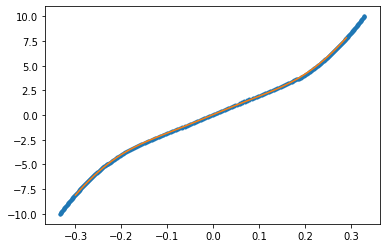

In [6]:
fields = np.arange(-0.3, 0.3, 0.01)
plt.plot(measured['Xfield'], measured['V'],'.')
plt.plot(fields, base_volt_calib(fields))

### Fit new Calibration

[ 1.28810939e+05  2.01787194e+03 -4.28164904e+04 -5.29265702e+02
  5.23758719e+03  4.70054300e+01 -1.33265366e+02 -5.54186600e-01
  1.95964079e+01  4.38837328e-02]


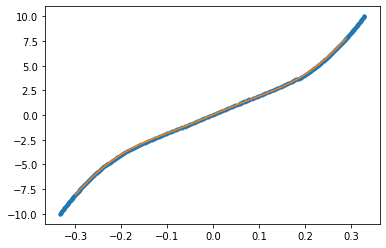

In [7]:
base_volt_coeff_new = np.polyfit(measured['Xfield'], measured['V'], 9)
base_volt_calib_new = np.poly1d(base_volt_coeff_new)
print(base_volt_coeff_new)
plt.plot(measured['Xfield'], measured['V'], '.')
fields = np.arange(-0.3, 0.3, 0.01)
plt.plot(fields, base_volt_calib_new(fields))
#save to volt_center (base_volt)

### Compare with old calibration

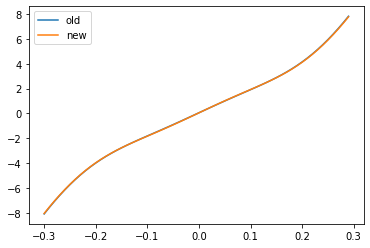

In [8]:
plt.plot(fields, base_volt_calib(fields), label = 'old')
plt.plot(fields, base_volt_calib_new(fields), label = 'new')
plt.legend()

### Check with 90deg

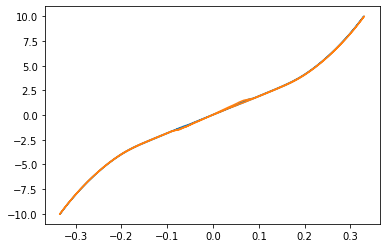

In [9]:
measured90deg = pd.read_csv('2026-06-12/phi90_daedalus_voltCenter_calib_2026-06-12_1.csv', comment = '#')
plt.plot(measured['Xfield'], measured['V'])
plt.plot(measured90deg['Yfield'], measured90deg['V'])